## Using Jieba, Stopwords, Matplotlib for Chinese Word Cloud

In [1]:
import jieba
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

## Load stopwords file (baidu_stopwords for Chinese)

In [2]:
stopwords = set(STOPWORDS)  # stopwords for English
print(stopwords)

{'same', 'hence', 'itself', 'under', "haven't", 'there', 'her', 'its', 'other', 'get', 'when', 'has', 'off', 'your', 'to', 'the', "couldn't", 'against', 'between', 'had', "you've", 'since', 'where', 'once', "shan't", 'themselves', 'no', 'very', "doesn't", 'have', "mustn't", 'ought', "they're", "isn't", 'some', "i've", 'few', "she'd", 'an', 'and', 'cannot', 'below', "he's", "aren't", 'further', 'yourselves', 'k', "he'll", 'http', 'them', "didn't", 'each', "she'll", 'again', 'about', 'here', 'down', "i'm", 'whom', 'while', 'himself', "you're", 'be', "hasn't", 'so', "that's", "wasn't", "don't", 'he', "how's", 'ours', 'hers', 'however', 'did', 'ourselves', 'his', 'such', 'that', 'in', 'my', 'shall', "i'll", 'our', 'it', 'would', 'am', 'yourself', 'during', 'only', 'why', "you'd", 'should', 'above', 'up', 'also', "it's", 'their', 'these', 'otherwise', 'com', 'over', "i'd", 'we', 'into', "we've", 'who', 'through', 'www', 'those', "there's", "weren't", 'r', 'this', 'if', 'more', 'me', "who's"

In [3]:
#add stop words for Chinese
swFile = open('data/baidu_stopwords.txt', encoding='UTF-8')
for line in swFile:
    stopwords.add(line.strip('\n'))
    
print(stopwords) 

{'hereby', 'hence', '恰恰相反', 'behind', '即便', '上下', '反之', '就', '来着', 'trying', '之一', 'eight', '叮咚', '任何', 'nearly', '怎样', 'http', '不拘', 'eg', '来', '否则', 'ours', 'away', '鉴于', '召开', '双方', '认真', '如果', 'hardly', '人们', '别说', 'somewhere', '例如', '大家', 'over', 'cause', '喏', '将', 'everyone', '既', '至', '自个儿', 'even', '不会', '哟', '任凭', 'presumably', '彻底', '她的', '及其', '还是', '多少', 'sent', 'theirs', '一片', '哪边', '为', 'having', 'herein', 'how', 'certainly', '专门', "we'll", '宁可', 'seems', 'former', '果然', '以至', '以外', '容易', '却不', 'seeing', 'there', '各级', 'though', 'off', 'looks', '当前', '既是', '高兴', 'beforehand', '不成', '分别', '前面', '咚', '适用', 'specifying', "he's", '不要', 'ok', '那儿', '充分', '人', '除非', '较之', '别的', '只是', '在下', '总之', '适当', "how's", '严格', '不可', '的', 'alone', 'far', '嘻', 'our', 'thru', 'yourself', '周围', 'sensible', '一下', '而言', 'name', '嗡嗡', 'up', '那个', 'currently', 'follows', '复杂', '并不是', 'com', '我', '另', 'www', '时', '哪年', '据', 'me', 'not', 'vs', 'saying', 'upon', 'downwards', 'else', '并没有', '与否', 'am

In [4]:
# you can also add your stop words 
#stopwords.add("我的停止词汇")
#print(stopwords) 

## Generate and show word cloud, you may need a Chinese font

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\ol\AppData\Local\Temp\jieba.cache
Loading model cost 0.652 seconds.
Prefix dict has been built successfully.


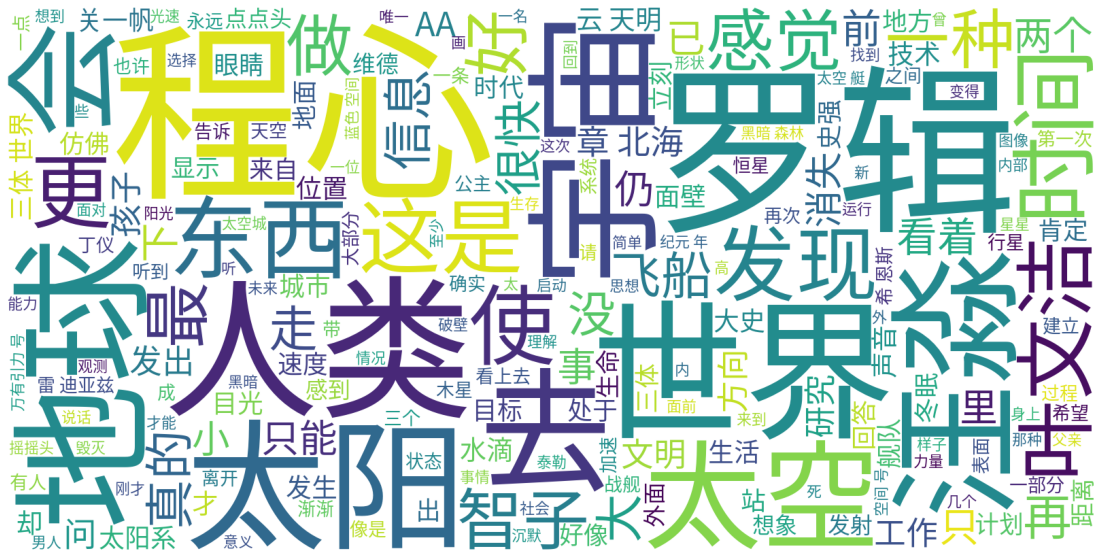

In [5]:
# Load a text file, use Jieba for cutting
textFile = 'data/santi.txt'
text = open(textFile, encoding='utf-8').read()
wordlist = jieba.cut(text)

#plot a word cloud for this text file

# supply a chinses font 
# font_path='data/NotoSansCJK-Regular.otf'
wordcloud = WordCloud(stopwords=stopwords, width=1600, height=800, background_color='white', \
                   font_path='data/NotoSansCJK-Regular.otf' ).generate(" ".join(wordlist))

plt.figure(figsize=(20,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

## You can also include a picture mask for the result

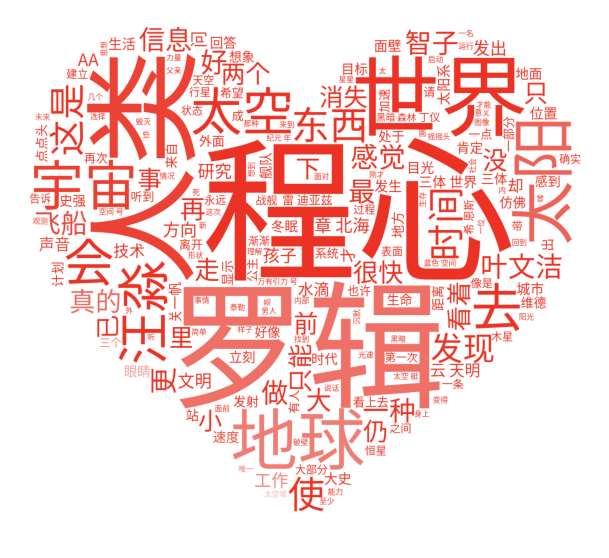

In [6]:
# Load a text file, use Jieba for cutting
textFile = 'data/santi.txt'
text = open(textFile, encoding='utf-8').read()
wordlist = jieba.cut(text)

# create a word cloud for this text file
import numpy as np
from PIL import Image
from wordcloud import ImageColorGenerator

background_image = np.array(Image.open('data/heart.jpg'))
#background_image = np.array(Image.open('data/balloon.jpg'))

# mask=background_image
wordcloud = WordCloud(stopwords=stopwords, mask=background_image, width=1252, height=1144, background_color='white', \
                      font_path='data/NotoSansCJK-Regular.otf').generate(" ".join(wordlist))

plt.figure(figsize=(20,10))

image_colors = ImageColorGenerator(background_image)
plt.imshow(wordcloud.recolor(color_func=image_colors))

plt.axis('off')
plt.show()

## The word ranking from Jieba analyse should be quite the same, you can include the weights for words

In [7]:
import jieba.analyse
textFile = 'data/santi.txt'
with open(textFile, encoding='utf-8') as file:
    text = file.readlines()
    keywords = jieba.analyse.extract_tags(str(text), topK = 300, withWeight=True)
    print(keywords)

#text = open(textFile, encoding='utf-8').read()
#keywords = jieba.analyse.extract_tags(str(text), topK = 300, withWeight=True)
#print(keywords)

[('程心', 0.05689920708552318), ('罗辑', 0.05138604426880459), ('三体', 0.03897090662810242), ('一个', 0.03082770398393317), ('太空', 0.028452911347181243), ('汪淼', 0.02613491686398661), ('宇宙', 0.02456451664143705), ('没有', 0.023582245757787234), ('地球', 0.022939645205068207), ('智子', 0.02285289590434449), ('他们', 0.021032553787394045), ('飞船', 0.020325886726742917), ('叶文洁', 0.019948390649806202), ('世界', 0.01957278518800754), ('人类', 0.019326475563197693), ('看到', 0.019146793361384706), ('我们', 0.01881538513198306), ('现在', 0.01782979923604296), ('太阳', 0.01756159319307941), ('舰队', 0.017560944011339254), ('自己', 0.017189729752716633), ('这个', 0.017091855155188886), ('面壁', 0.016006558623718144), ('可能', 0.01567500377400361), ('已经', 0.01547345467926748), ('知道', 0.01537537812462816), ('AA', 0.014898165168842608), ('什么', 0.014867272628715662), ('文明', 0.013740698672280813), ('太阳系', 0.013565441252130703), ('纪元', 0.01197729476593408), ('光速', 0.011892061849176622), ('u3000', 0.011657603818557634), ('你们', 0.0114581819

## You can also generate WordCloud from weights/keywords of Jieba

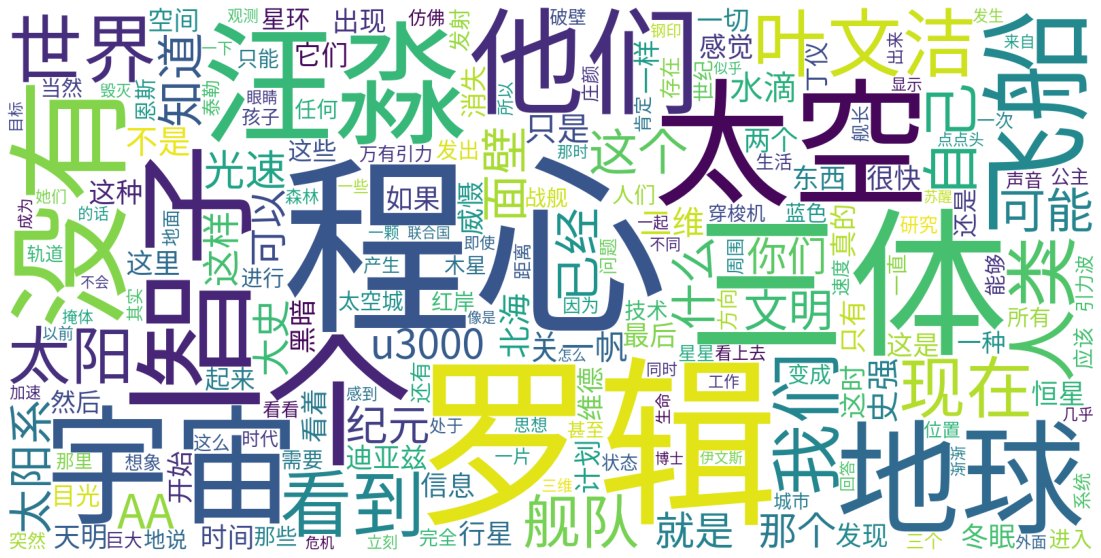

In [8]:
word_dict = {}
for i in keywords:
    word_dict[i[0]]=i[1]
        
wordcloud = WordCloud(stopwords=stopwords, width=1600, height=800, background_color='white', \
                      font_path='data/NotoSansCJK-Regular.otf').fit_words(word_dict)

plt.figure(figsize=(20,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()